In [5]:
if (!requireNamespace("mixOmics", quietly = TRUE)) {
    options(BioC_mirror = "https://bioconductor.org")
    BiocManager::install(version = "3.18", force = TRUE)
    BiocManager::install("mixOmics")
}

library(mixOmics)
library(BiocParallel)

# print mixomics version
packageVersion("mixOmics")

[1] ‘6.26.0’

In [2]:
DATA_DIR <- "/home/mariya/Data/pallas"
TRAIN_DATA_DIR <- file.path(DATA_DIR, "nf-core-mlomix-bimodal/finalize")
METH_TRAIN_FILE <- file.path(TRAIN_DATA_DIR, "features.dnam.csv")
GEX_TRAIN_FILE <- file.path(TRAIN_DATA_DIR, "features.gex.csv")
LABELS_TRAIN_FILE <- file.path(TRAIN_DATA_DIR, "labels.csv")
OUTPUT_DIR <- file.path(DATA_DIR, "mixOmics")

In [4]:
source("helpers.R")
train_data <- data(GEX_TRAIN_FILE, METH_TRAIN_FILE, LABELS_TRAIN_FILE)

Samples: 1200 
GEX features: 5000 
DNAm features: 5000 
Subtypes: AML, APL-PML::RARA AML, BCR::ABL1 AML, CBFA2T3::GLIS2 AML, CBFB::MYH11 AML, CEBPAalt AML, DEK::NUP214 AML, ETV6-r AML, FUS::ERG AML, KAT6A-r AML, KMT2A-r AML, NPM1alt AML, NUP98-r AML, RBM15::MKL1 AML, RUNX1::RUNX1T1 B-ALL, BCR::ABL1 B-ALL, BCR::ABL1-like B-ALL, DUX4-r B-ALL, ETV6::RUNX1 B-ALL, ETV6::RUNX1-like B-ALL, high hyperdiploid B-ALL, iAMP21 B-ALL, KMT2A-r B-ALL, MEF2D-r B-ALL, PAX5 P80R B-ALL, PAX5alt B-ALL, TCF3::PBX1 B-ALL, ZNF384-r Non-leukemic T-ALL 


In [4]:
X_gex_train <- train_data$X_gex
X_dnam_train <- train_data$X_dnam
Y_train     <- train_data$Y

head(X_gex_train)
head(X_dnam_train)
head(Y_train)

,ENSG00000254772,ENSG00000196230,ENSG00000136167,ENSG00000120129,ENSG00000152518,ENSG00000130066,ENSG00000147127,ENSG00000145741,ENSG00000278677,ENSG00000116703,⋯,ENSG00000082146,ENSG00000091592,ENSG00000174898,ENSG00000152086,ENSG00000171992,ENSG00000288611,ENSG00000176438,ENSG00000223638,ENSG00000258102,ENSG00000164308
ALL_1005,12.22242,11.17626,10.160699,11.486188,6.540606,7.217236,-1.094014,9.360560,11.84936,-1.094014,⋯,6.886751,4.114954,-1.094014,-1.094014,1.0662768,-1.094014,5.458880,-1.0940139,-0.7031547,6.789474
ALL_1019,12.08865,10.54901,10.489349,12.638029,9.797654,10.625313,-1.094014,8.812944,12.20442,-1.094014,⋯,5.498455,5.397781,2.373984,-1.094014,-0.8899929,-1.094014,5.373216,1.2655482,1.4874872,6.274038
ALL_1023,12.27273,11.57122,9.064830,11.459523,10.090340,8.850153,-1.094014,8.844418,13.47757,-1.094014,⋯,6.044226,5.045265,1.616204,-1.094014,-0.7939539,-1.094014,5.853435,-0.8194423,2.3249591,6.452241
ALL_1026,12.82470,10.45617,10.432240,10.375256,9.777508,7.260263,-1.094014,9.209032,12.22074,-1.094014,⋯,6.154586,5.454379,-1.094014,-1.094014,2.1073910,-1.094014,5.397750,-1.0940139,3.8058915,4.429520
ALL_1039,12.56007,10.24231,11.143276,12.628202,9.568757,11.666583,-1.094014,9.294973,12.37270,-1.094014,⋯,4.878057,6.262360,-1.094014,-1.094014,-0.5476755,-1.094014,6.124074,-1.0940139,3.8703710,7.071240
ALL_1047,13.16769,12.19197,9.890358,9.704086,10.682779,8.398338,-1.094014,9.571006,13.40136,-1.094014,⋯,4.767217,5.308694,1.710755,-1.094014,-0.9786790,-1.094014,5.194296,-1.0940139,2.5881950,4.165885


,cg09698465,cg20439288,cg07110356,cg25670583,cg18559579,cg17353893,cg23478547,cg25588389,cg01030534,cg22301418,⋯,cg21946195,cg08233654,cg22504204,cg20232986,cg06557644,cg16530382,cg11006453,cg03430846,cg11433098,cg12691572
ALL_1005,0.6444,0.0292,0.9767,0.9345,0.9466,0.9812,0.9689,0.0184,0.0606,0.0853,⋯,0.6754,0.6514,0.9654,0.9272,0.2460,0.7725,0.9704,0.9472,0.5403,0.9257
ALL_1019,0.3499,0.0218,0.1615,0.9477,0.5065,0.9802,0.9779,0.0224,0.0402,0.0492,⋯,0.6185,0.0154,0.5325,0.9454,0.1131,0.0502,0.0491,0.7849,0.0738,0.0624
ALL_1023,0.9817,0.0167,0.9815,0.9475,0.9583,0.9842,0.9843,0.1072,0.0401,0.1176,⋯,0.5967,0.8047,0.3981,0.8947,0.1162,0.0667,0.9592,0.8576,0.0891,0.9636
ALL_1026,0.3219,0.0245,0.2155,0.9514,0.9606,0.9437,0.9824,0.0342,0.0327,0.0784,⋯,0.6373,0.0322,0.9324,0.9077,0.1178,0.0753,0.0326,0.9313,0.0690,0.0890
ALL_1039,0.9793,0.0216,0.9576,0.9485,0.9470,0.9800,0.9558,0.6030,0.0354,0.1527,⋯,0.6972,0.3196,0.2391,0.2638,0.1710,0.0695,0.8935,0.4152,0.2011,0.7794
ALL_1047,0.9705,0.0298,0.9758,0.9202,0.9368,0.9748,0.9772,0.0323,0.1199,0.0366,⋯,0.9406,0.9241,0.9720,0.8959,0.0362,0.1035,0.9439,0.9385,0.0379,0.9378


[1] B-ALL, MEF2D-r          B-ALL, ZNF384-r         B-ALL, ETV6::RUNX1     
[4] B-ALL, PAX5alt          B-ALL, BCR::ABL1        B-ALL, ETV6::RUNX1-like
29 Levels: AML, APL-PML::RARA AML, BCR::ABL1 ... T-ALL

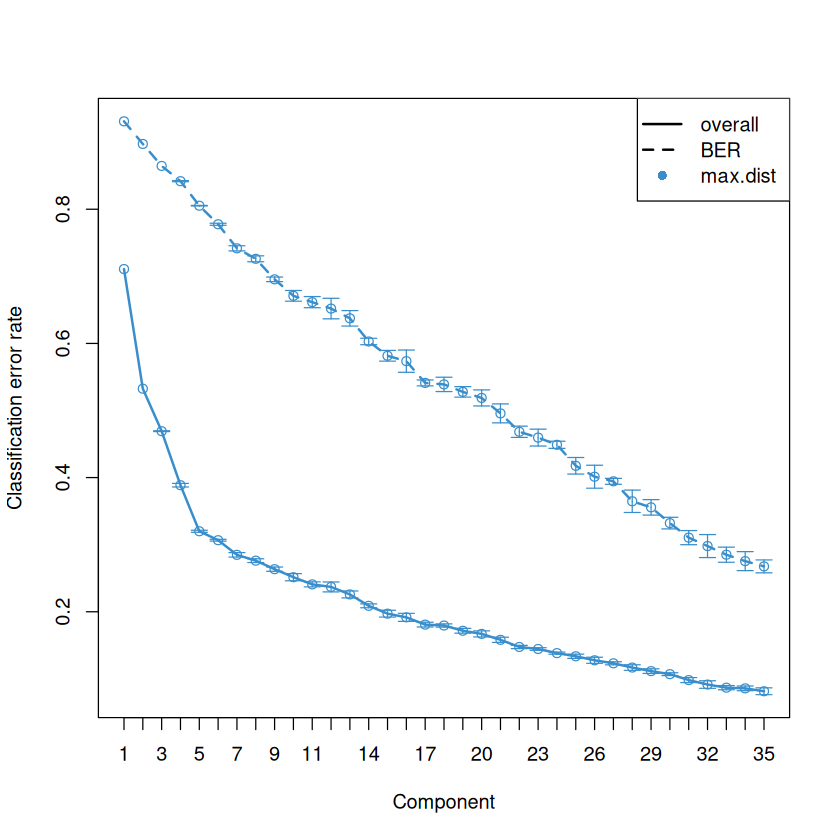

In [5]:
FOLDS     <- 3
NREPEAT   <- 5
MAX_NCOMP <- 35
KEEP_X    <- 500
DIST      <- "max.dist"
bpparam <- MulticoreParam(workers = parallel::detectCores() - 1)

gex_prelim <- splsda(X_gex_train, Y_train,
                     ncomp = MAX_NCOMP,
                     keepX = rep(KEEP_X, MAX_NCOMP))
gex_perf   <- perf(gex_prelim,
                   validation  = "Mfold",
                   folds       = FOLDS,
                   nrepeat     = NREPEAT,
                   dist        = DIST,
                   BPPARAM     = bpparam,
                   progressBar = FALSE)

# Plot BER across all components to see the curve shape
plot(gex_perf, criterion = "BER")

Warning message:
“The SGCCA algorithm did not converge”
Warning message:
“The SGCCA algorithm did not converge”


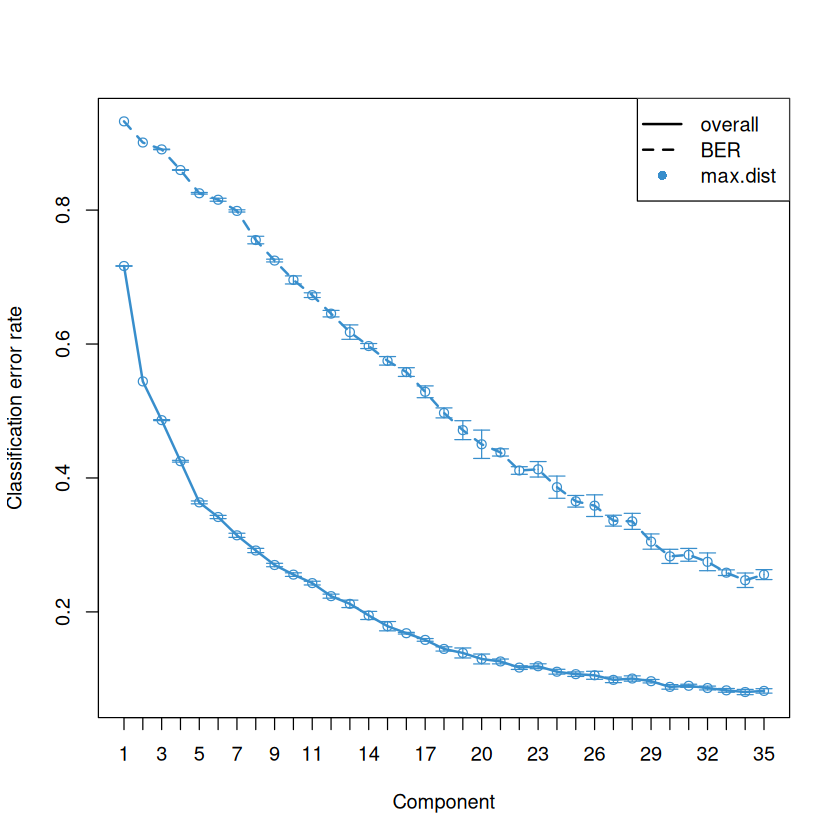

In [6]:
# ============================================================
# DNAm
# ============================================================
dnam_prelim <- splsda(X_dnam_train, Y_train,
                      ncomp = MAX_NCOMP,
                      keepX = rep(KEEP_X, MAX_NCOMP))
dnam_perf   <- perf(dnam_prelim,
                    validation  = "Mfold",
                    folds       = FOLDS,
                    nrepeat     = NREPEAT,
                    dist        = DIST,
                    BPPARAM     = bpparam,
                    progressBar = FALSE)
plot(dnam_perf, criterion = "BER")

Design matrix has changed to include Y; each block will be
            linked to Y.



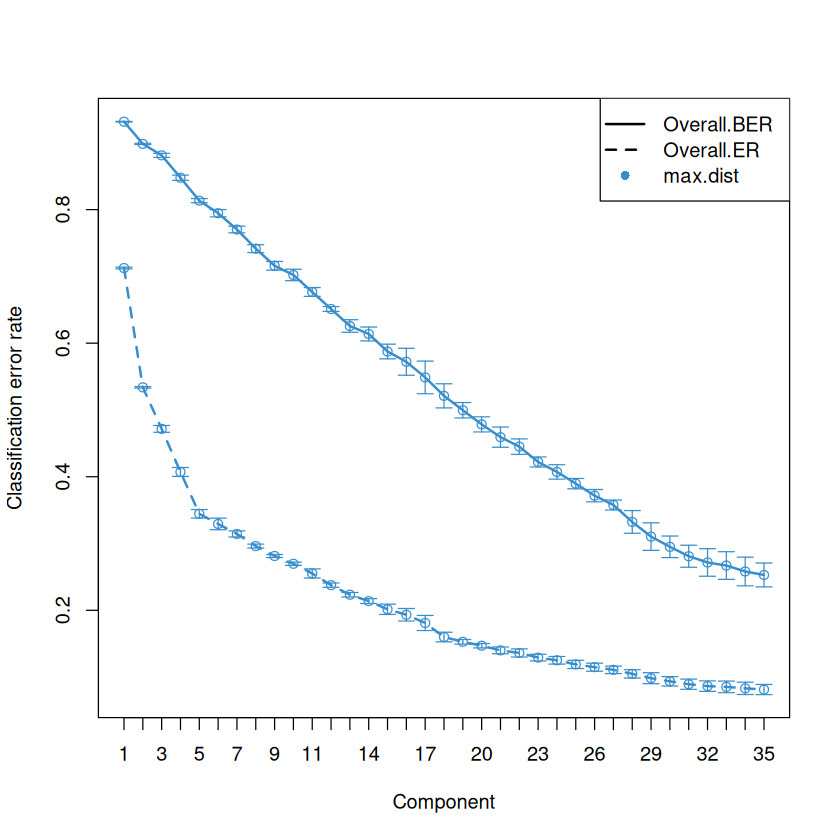

In [7]:
# ============================================================
# DIABLO
# ============================================================
design       <- matrix(0.1, nrow = 2, ncol = 2,
                       dimnames = list(c("GEX","DNAm"), c("GEX","DNAm")))
diag(design) <- 0

blocks_train <- list(GEX = X_gex_train, DNAm = X_dnam_train)

diablo_prelim <- block.splsda(X      = blocks_train,
                               Y      = Y_train,
                               ncomp  = MAX_NCOMP,
                               keepX  = list(GEX  = rep(KEEP_X, MAX_NCOMP),
                                             DNAm = rep(KEEP_X, MAX_NCOMP)),
                               design = design)
diablo_perf   <- perf(diablo_prelim,
                      validation  = "Mfold",
                      folds       = FOLDS,
                      nrepeat     = NREPEAT,
                      dist        = DIST,
                      BPPARAM     = bpparam,
                      progressBar = FALSE)
plot(diablo_perf, criterion = "BER")

In [10]:
saveRDS(gex_perf,    file.path(OUTPUT_DIR, "gex_perf.rds"))
saveRDS(dnam_perf,   file.path(OUTPUT_DIR, "dnam_perf.rds"))
saveRDS(diablo_perf, file.path(OUTPUT_DIR, "diablo_perf.rds"))

In [11]:
# ============================================================
# Extract optimal ncomp for each
# ============================================================
ncomp_gex    <- gex_perf$choice.ncomp["BER", "max.dist"]
ncomp_dnam   <- dnam_perf$choice.ncomp["BER", "max.dist"]
ncomp_diablo <- diablo_perf$choice.ncomp$WeightedVote["Overall.BER", 1]

cat("Optimal ncomp — GEX:", ncomp_gex,
    " DNAm:", ncomp_dnam,
    " DIABLO:", ncomp_diablo, "\n")

Optimal ncomp — GEX: 33  DNAm: 33  DIABLO: 34 


In [12]:
# GEX
cat("=== GEX BER per component ===\n")
print(round(gex_perf$error.rate$BER[, "max.dist"], 3))

# DNAm
cat("\n=== DNAm BER per component ===\n")
print(round(dnam_perf$error.rate$BER[, "max.dist"], 3))

# DIABLO
cat("\n=== DIABLO BER per component ===\n")
diablo_ber <- colMeans(diablo_perf$WeightedVote.error.rate$max.dist)
print(round(diablo_ber, 3))

=== GEX BER per component ===
 comp1  comp2  comp3  comp4  comp5  comp6  comp7  comp8  comp9 comp10 comp11 
 0.931  0.897  0.865  0.842  0.805  0.778  0.742  0.726  0.696  0.671  0.662 
comp12 comp13 comp14 comp15 comp16 comp17 comp18 comp19 comp20 comp21 comp22 
 0.652  0.637  0.603  0.582  0.574  0.541  0.539  0.528  0.519  0.496  0.468 
comp23 comp24 comp25 comp26 comp27 comp28 comp29 comp30 comp31 comp32 comp33 
 0.460  0.449  0.418  0.401  0.394  0.365  0.356  0.332  0.310  0.298  0.285 
comp34 comp35 
 0.275  0.268 

=== DNAm BER per component ===
 comp1  comp2  comp3  comp4  comp5  comp6  comp7  comp8  comp9 comp10 comp11 
 0.932  0.901  0.891  0.860  0.825  0.815  0.799  0.755  0.725  0.696  0.673 
comp12 comp13 comp14 comp15 comp16 comp17 comp18 comp19 comp20 comp21 comp22 
 0.645  0.618  0.597  0.575  0.558  0.529  0.497  0.471  0.450  0.438  0.411 
comp23 comp24 comp25 comp26 comp27 comp28 comp29 comp30 comp31 comp32 comp33 
 0.413  0.386  0.365  0.359  0.336  0.335  0.305  

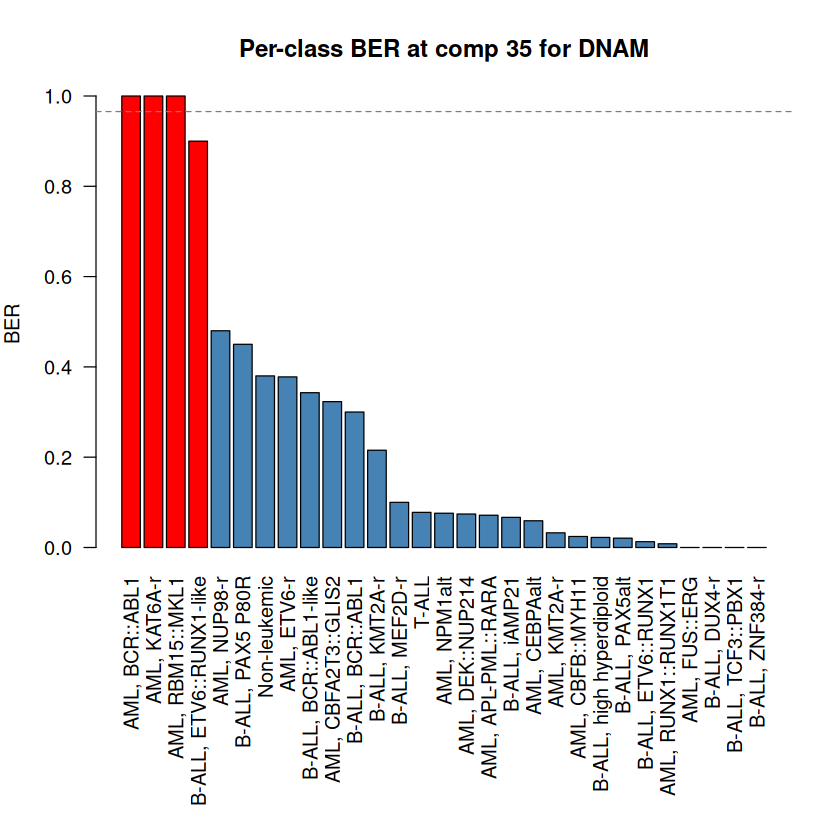

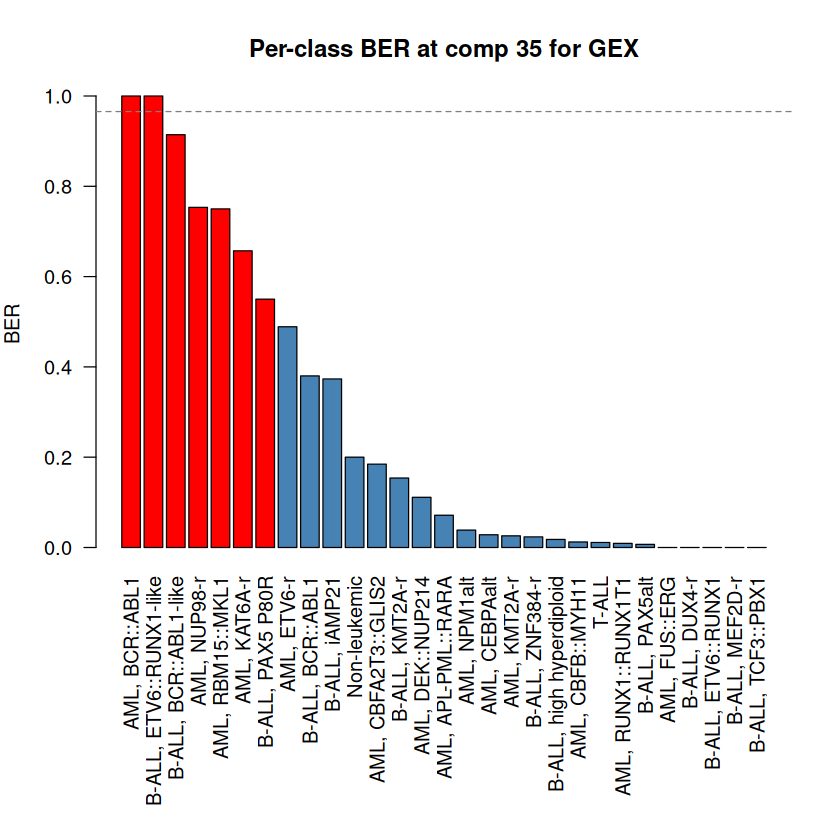

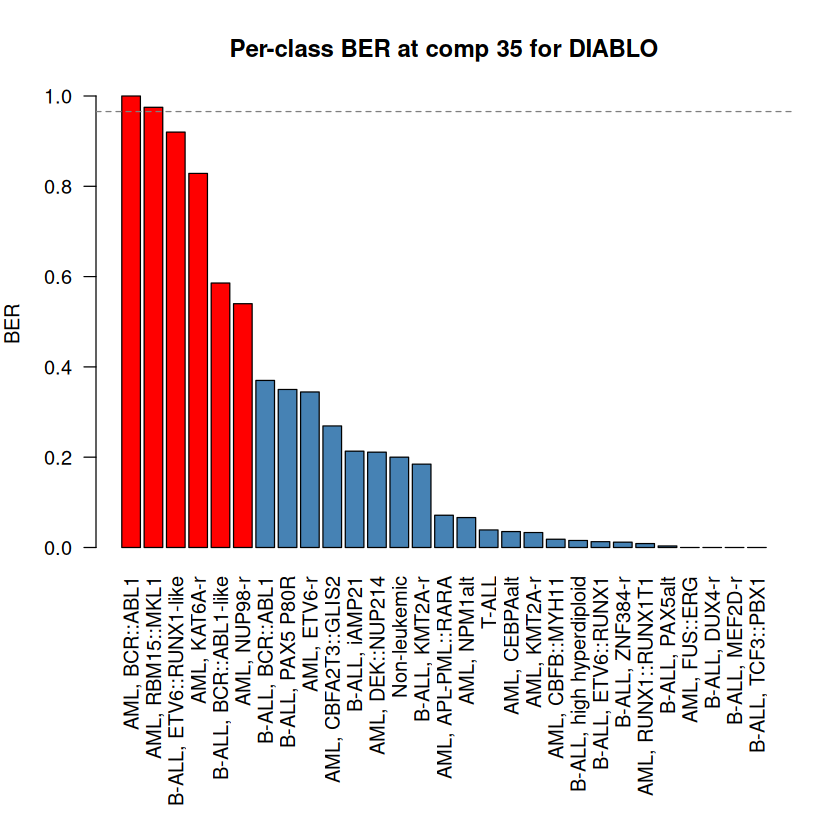

In [25]:
comp_num <- 35

dnam_ber   <- dnam_perf$error.rate.class$max.dist[, paste0("comp", comp_num)]
gex_ber    <- gex_perf$error.rate.class$max.dist[, paste0("comp", comp_num)]
diablo_ber <- rowMeans(cbind(
  diablo_perf$error.rate.per.class$GEX$max.dist[, paste0("comp", comp_num)],
  diablo_perf$error.rate.per.class$DNAm$max.dist[, paste0("comp", comp_num)]
))

plot_per_class_ber <- function(ber, comp_num, model_name) {
  ber_sorted <- sort(ber, decreasing = TRUE)
  par(mar = c(12, 4, 4, 2))  # bottom, left, top, right
  barplot(
    ber_sorted,
    las = 2,
    ylab = "BER",
    main = paste("Per-class BER at comp", comp_num, "for", model_name),
    col = ifelse(ber_sorted > 0.5, "red", "steelblue")
  )
  abline(h = 1 - 1/nlevels(Y_train), lty = 2, col = "grey50")
}

# Sort and view
plot_per_class_ber(dnam_ber, comp_num, "DNAM")
plot_per_class_ber(gex_ber, comp_num, "GEX")
plot_per_class_ber(diablo_ber, comp_num, "DIABLO")


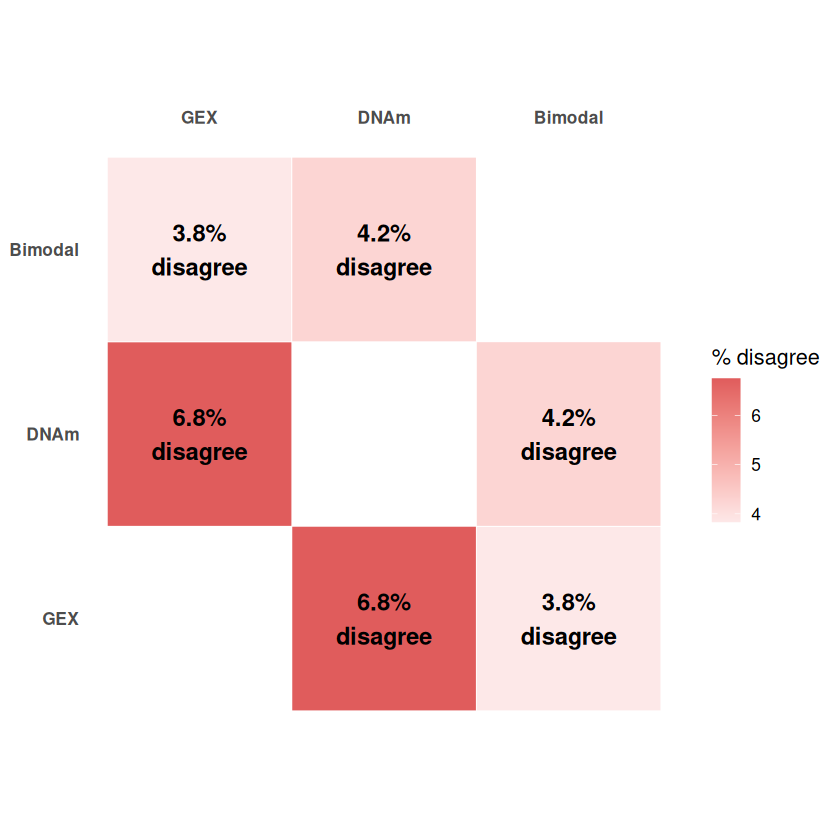

In [17]:
# Compute pairwise disagreement
gex_vs_dnam    <- mean(gex_pred != dnam_pred) * 100
gex_vs_diablo  <- mean(gex_pred != diablo_pred) * 100
dnam_vs_diablo <- mean(dnam_pred != diablo_pred) * 100

# Build symmetric matrix
modalities <- c("GEX", "DNAm", "Bimodal")
disagree_mat <- matrix(NA, nrow = 3, ncol = 3,
                       dimnames = list(modalities, modalities))

disagree_mat["GEX",     "DNAm"]    <- gex_vs_dnam
disagree_mat["DNAm",    "GEX"]     <- gex_vs_dnam
disagree_mat["GEX",     "Bimodal"] <- gex_vs_diablo
disagree_mat["Bimodal", "GEX"]     <- gex_vs_diablo
disagree_mat["DNAm",    "Bimodal"] <- dnam_vs_diablo
disagree_mat["Bimodal", "DNAm"]    <- dnam_vs_diablo

# Plot
library(ggplot2)
library(reshape2)

mat_df <- melt(disagree_mat, na.rm = TRUE)
colnames(mat_df) <- c("Row", "Col", "Disagreement")

ggplot(mat_df, aes(x = Col, y = Row, fill = Disagreement)) +
  geom_tile(color = "white") +
  geom_text(aes(label = sprintf("%.1f%%\ndisagree", Disagreement)),
            size = 5, fontface = "bold") +
  scale_fill_gradient(low = "#fde8e8", high = "#e05c5c",
                      name = "% disagree") +
  scale_x_discrete(position = "top") +
  theme_minimal(base_size = 13) +
  theme(axis.title = element_blank(),
        panel.grid = element_blank(),
        axis.text = element_text(face = "bold")) +
  coord_fixed()